In [1]:
# # On Google Colab, uncomment this cell and run it first.
# # Upload tallinn_osrm_matrix.json and golden_quantum_tsp_angles.npz next to the notebook.
# !pip install -q qiskit numba pylatexenc

# Golden quantum solution: one vehicle, one route

This notebook solves toy problem 1 from the repository `README.md`: the travelling salesperson problem (TSP) on the Tallinn locations in `tallinn_osrm_matrix.json`. It is the reference to compare our other quantum solutions against. The leaderboard is in `solutions/README.md`.

**Result.** On all 10 locations the circuit uses 82 qubits and has 362,880 valid tours to choose from. The best circuit has 20 layers and returns the shortest tour (40.205 km) in 98.8 % of shots. Random guessing finds it in 0.00055 % of shots.

| Angle tuning | Layers | P(opt): shots that are a shortest tour | Shots for a 99 % chance |
|---|---|---|---|
| Linear ramp, 2 tuned numbers | 20 / 40 / 80 | 17.9 % / 57.3 % / 90.9 % | 24 / 6 / 2 |
| One mixer angle per layer | 20 / 40 | 48.7 % / 79.8 % | 7 / 3 |
| One mixer angle per move | 10 / 20 | 54.3 % / 98.8 % | 6 / 2 |
| Random guessing | | 0.00055 % | 835,560 |

The same circuit also solves the real one-way road distances: 99.5 % of shots return the true shortest route, 40.30 km (section 11).

These numbers come from the saved angles. The cells below recompute every one of them.

**How it gets there**

1. **No invalid answers.** One qubit says "location v is visited at step t". The circuit starts in an equal mix of all valid tours and every gate keeps it there. There are no penalty terms, and every shot is a valid tour.
2. **A mixer that knows the problem.** The mixer reverses a stretch of the route, which is the classical 2-opt move. A reversal changes only two roads, so good tours sit next to good tours.
3. **Exact simulation of 82 qubits.** The state never leaves the valid tours, so the simulator stores one amplitude per tour (362,880 for 10 locations) instead of 2⁸² amplitudes. A real Qiskit circuit confirms this on 4 and 5 locations.
4. **Three levels of angle tuning.** A linear ramp with two numbers, then one mixer angle per layer, then one mixer angle per move. Exact gradients come from adjoint differentiation.

**What this is not**

- It is not a speed-up over classical computing. Ten locations take a laptop milliseconds, and the simulator itself lists every tour.
- It does not run on today's quantum computers. The circuit needs 82 qubits and far more gates than current error rates allow. Section 12 gives the numbers.

**How to run**

Run all cells. With the saved angles in `golden_quantum_tsp_angles.npz` this takes a few minutes. Set `RETRAIN = True` to train again from scratch. That takes about 1.5 hours with `numba` installed (`uv add numba`). Without `numba` it is 5 to 25 times slower, so expect a day.

# 1. Setup

In [2]:
import itertools
import json
import math
import time
from collections import Counter
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from scipy.optimize import minimize

try:
    import numba
except ImportError:
    numba = None  # the NumPy simulator below is used instead; it is 5 to 25 times slower

In [3]:
N_LOCATIONS = 10                 # the depot plus 9 stops: every point in the data set
RETRAIN = False                  # True: ignore the saved angles and train again
ANGLE_FILE = Path("golden_quantum_tsp_angles.npz")
GIBBS_ETA = 8.0                  # how sharply training focuses on the shortest tours
SHOTS = 1000
SEED = 7

DEPTHS_RAMP = (5, 10, 20, 40, 80, 160)   # layers tried with a linear ramp
DEPTHS_PER_LAYER = (5, 10, 20, 40)       # layers trained with one mixer angle per layer
DEPTHS_PER_MOVE = (5, 10, 20)            # layers trained with one mixer angle per move
SHOWCASE = ("per move", 20)              # the circuit sampled in section 8

In [4]:
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2, "lines.markersize": 7,
    "axes.titlelocation": "left", "axes.titleweight": "bold", "legend.frameon": False, "figure.dpi": 110,
})


def show_table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |", "|" + "---|" * len(headers)]
    lines += ["| " + " | ".join(str(cell) for cell in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


def pct(x):
    return f"{100 * x:.1f} %" if x >= 0.001 else f"{100 * x:.2g} %"

# 2. The problem

One van leaves the depot, visits every stop once and returns. We minimise the total road distance.

Real road distances depend on direction. The README tells us to use one distance per pair of locations, taken from the upper half of the matrix: the distance from the lower-numbered point to the higher-numbered one. Sections 3 to 9 follow that rule. Section 11 solves the problem again with the real one-way distances.

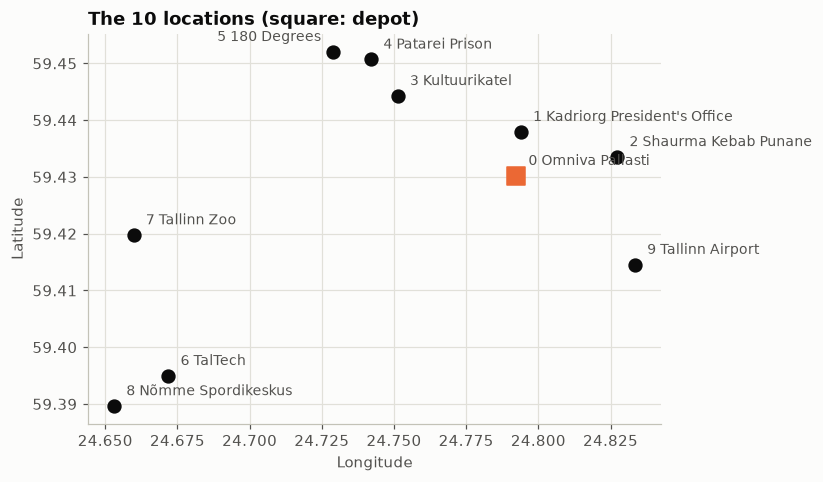

In [5]:
DATA_FILE = next(path for path in (Path("tallinn_osrm_matrix.json"), Path("../tallinn_osrm_matrix.json")) if path.exists())
data = json.loads(DATA_FILE.read_text(encoding="utf-8"))
ROAD_KM = np.array(data["distances"], dtype=float) / 1000
NAMES = [point["name"] for point in data["points"]]
LON_LAT = np.array([(point["lon"], point["lat"]) for point in data["points"]])


def distances(n, directed=False):
    """Distance matrix in km for the first n locations. Symmetric (upper half) unless `directed`."""
    road = ROAD_KM[:n, :n]
    if directed:
        return road.copy()
    upper = np.triu(road)
    return upper + upper.T


def draw_map(ax, n, tour=None):
    """Locations on a longitude and latitude grid. A tour is drawn with straight lines, not along roads."""
    lon, lat = LON_LAT[:n, 0], LON_LAT[:n, 1]
    if tour is not None:
        loop = [0, *tour, 0]
        ax.plot(lon[loop], lat[loop], color=BLUE, zorder=2)
    ax.scatter(lon[1:], lat[1:], s=70, color=INK, zorder=3)
    ax.scatter(lon[:1], lat[:1], s=140, color=ORANGE, marker="s", zorder=3)
    for i in range(n):
        # Point 5 sits just left of point 4, so its label goes on the other side.
        side = -1 if i == 5 else 1
        label = str(i) if tour is not None else f"{i} {NAMES[i].split(' (')[0]}"
        ax.annotate(label, (lon[i], lat[i]), xytext=(8 * side, 7), textcoords="offset points",
                    ha="right" if side < 0 else "left", fontsize=9, color="#52514e")
    ax.set_aspect(1 / math.cos(math.radians(lat.mean())))
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")


fig, ax = plt.subplots(figsize=(8, 4.6))
draw_map(ax, N_LOCATIONS)
ax.set_title(f"The {N_LOCATIONS} locations (square: depot)")
plt.show()

# 3. Every tour, and the exact answer

The depot is fixed as the start and the end. A tour is then an order of the other n − 1 locations, so there are (n − 1)! tours. For 10 locations that is 362,880.

We list them all. This gives the exact answer to check against, and the simulator in section 6 needs the list. A real quantum computer would not make this list.

`z` is the tour length as a z-score: the length minus the mean, divided by the standard deviation. The circuit uses `z` so that the same angles work for instances of any size. On hardware, the mean and the standard deviation would be estimated from a few hundred random tours.

In [6]:
def all_tours(n):
    """Every visiting order of locations 1..n-1, one row per tour, in dictionary order."""
    return np.array(list(itertools.permutations(range(1, n))), dtype=np.int8)


def tour_lengths(tours, d):
    order = tours.astype(np.int64)
    km = d[0, order[:, 0]] + d[order[:, -1], 0]
    for step in range(order.shape[1] - 1):
        km = km + d[order[:, step], order[:, step + 1]]
    return km


def tour_rank(tours):
    """Row number of each tour in `all_tours`."""
    m = tours.shape[1]
    rank = np.zeros(len(tours), dtype=np.int64)
    for step in range(m - 1):
        rank += (tours[:, step + 1:] < tours[:, step:step + 1]).sum(axis=1) * math.factorial(m - 1 - step)
    return rank


@dataclass(frozen=True)
class Instance:
    n: int               # locations, including the depot
    d: np.ndarray        # distance matrix used as the cost, km
    tours: np.ndarray    # every valid tour
    km: np.ndarray       # length of every tour
    z: np.ndarray        # length of every tour as a z-score
    best: np.ndarray     # True for the shortest tours


def make_instance(n, directed=False):
    d = distances(n, directed)
    tours = all_tours(n)
    km = tour_lengths(tours, d)
    return Instance(n, d, tours, km, (km - km.mean()) / km.std(), km <= km.min() + 1e-9)


inst = make_instance(N_LOCATIONS)
M = N_LOCATIONS - 1
best_tour = tuple(int(v) for v in inst.tours[inst.best][0])
P_RANDOM = inst.best.mean()

print(f"{len(inst.km):,} tours, {inst.best.sum()} of them shortest (one loop, driven in either direction)")
print(f"Shortest tour: {inst.km.min():.3f} km   0 → " + " → ".join(map(str, best_tour)) + " → 0")
print(f"Mean tour: {inst.km.mean():.2f} km ({inst.km.mean() / inst.km.min() - 1:.0%} longer)   longest: {inst.km.max():.2f} km")
print(f"Random guessing finds a shortest tour with probability {pct(P_RANDOM)}")

362,880 tours, 2 of them shortest (one loop, driven in either direction)
Shortest tour: 40.205 km   0 → 1 → 3 → 4 → 5 → 7 → 8 → 6 → 9 → 2 → 0
Mean tour: 72.68 km (81% longer)   longest: 93.04 km
Random guessing finds a shortest tour with probability 0.00055 %


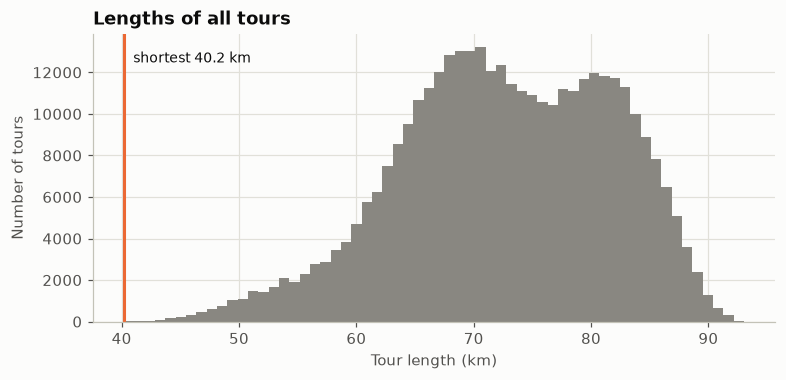

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(inst.km, bins=60, color=MUTED)
ax.axvline(inst.km.min(), color=ORANGE)
ax.annotate(f"shortest {inst.km.min():.1f} km", (inst.km.min(), ax.get_ylim()[1] * 0.9), xytext=(6, 0),
            textcoords="offset points", fontsize=9)
ax.set_title("Lengths of all tours"); ax.set_xlabel("Tour length (km)"); ax.set_ylabel("Number of tours")
plt.show()

# 4. The quantum model

## Qubits

We use the **position encoding**. Qubit (v, t) is 1 when stop v is visited at step t. With m = n − 1 stops this takes m² qubits, plus one helper qubit for the mixer: 82 qubits for 10 locations.

A valid tour has exactly one 1 in every row and every column of this m × m grid. Only 9! of the 2⁸¹ bitstrings are valid, a share of about 10⁻¹⁹. The usual fix is a penalty term that makes invalid bitstrings expensive. Our notes show how hard penalties are to tune, and most shots are still invalid.

## Staying inside the valid tours

This notebook uses the Quantum Alternating Operator Ansatz of Hadfield and others (reference 1) instead. It has the same layered shape as QAOA, with two changes:

- The **start state** is an equal superposition of all valid tours, not of all bitstrings.
- The **mixer** only moves amplitude from one valid tour to another.

The state then never contains an invalid tour. Penalties are not needed and every shot is usable.

## One layer

1. **Cost phase.** Each tour gets the phase exp(−iγ·z), where z is its length as a z-score. The length is a sum over consecutive steps, so this needs only one-qubit and two-qubit phase gates.
2. **2-opt mixer.** For each stretch of steps a..b, apply exp(+iβ·R), where R reverses the visiting order inside that stretch. R applied twice does nothing, so exp(+iβ·R) = cos β + i·sin β·R: the tour keeps amplitude cos β and passes i·sin β to its reversed neighbour.

Reversing a stretch of the route is the 2-opt move of classical TSP heuristics (reference 9). With symmetric distances it changes only the two roads at the ends of the stretch. Neighbouring tours therefore have similar lengths, and that is what lets the mixer steer amplitude towards short tours. Section 9 measures how much this matters.

In [8]:
def segments(m, include_full=False):
    """Step ranges (a, b) that the mixer reverses, shortest first.

    Reversing all m steps does not change a symmetric tour's length, so it is only used with one-way distances.
    """
    return [(a, a + length - 1) for length in range(2, m + include_full) for a in range(m - length + 1)]


def reversal_moves(m, include_full=False):
    moves = []
    for a, b in segments(m, include_full):
        order = list(range(m))
        order[a:b + 1] = order[a:b + 1][::-1]
        moves.append(order)
    return moves


def swap_moves(m, adjacent_only):
    """Exchange the stops at two steps: the mixer family of reference 1, kept for the comparison in section 9."""
    moves = []
    for a in range(m):
        for b in range(a + 1, a + 2 if adjacent_only else m):
            if b < m:
                order = list(range(m))
                order[a], order[b] = order[b], order[a]
                moves.append(order)
    return moves


print(f"{len(segments(M))} reversal moves per layer for {N_LOCATIONS} locations")

35 reversal moves per layer for 10 locations


# 5. The circuit, gate by gate

These functions build the real circuit in Qiskit. We use them twice: to check the simulator on small instances (section 6), and to count gates for the full 82-qubit circuit (section 12).

- **Start state.** A quantum version of the Fisher–Yates shuffle. Step t first picks one of the m − t free "slots" with a W state, an equal superposition of all strings with a single 1. Controlled swaps then turn slots into stops, so that no stop is used twice. It needs no helper qubits.
- **Cost phase.** One phase gate per qubit for the roads to and from the depot, and one controlled-phase gate for every pair "stop u at step t, stop v at step t + 1".
- **Mixer.** R has eigenvalues +1 and −1. A helper qubit reads which one applies (Hadamard, controlled reversal, Hadamard). A Z rotation on the helper then adds the phase, and the same three gates in reverse clean the helper up.

Start state for 4 locations (3 stops, 9 qubits):


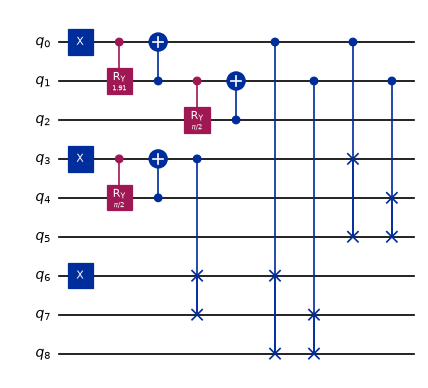

In [9]:
def qubit(stop, step, m):
    """Index of the qubit that is 1 when stop `stop` (0..m-1) is visited at step `step`."""
    return step * m + stop


def w_state(qc, qubits):
    """Equal superposition of all strings with a single 1 on `qubits`."""
    qc.x(qubits[0])
    for i in range(len(qubits) - 1):
        # Keep amplitude sqrt(1/(k-i)) on qubit i and pass the rest on to qubit i+1.
        qc.cry(2 * math.acos(math.sqrt(1 / (len(qubits) - i))), qubits[i], qubits[i + 1])
        qc.cx(qubits[i + 1], qubits[i])


def all_tours_state(qc, m):
    """Equal superposition of all m! valid tours."""
    for step in range(m):
        w_state(qc, [qubit(slot, step, m) for slot in range(m - step)])
    # Step `earlier` took slot j, so from then on slot j stands for the last slot that was still free.
    for step in range(m - 1, 0, -1):
        for earlier in range(step - 1, -1, -1):
            for j in range(m - 1 - earlier):
                qc.cswap(qubit(j, earlier, m), qubit(j, step, m), qubit(m - 1 - earlier, step, m))


def cost_phase(qc, gamma, instance):
    """exp(-i gamma z) on valid tours, up to a global phase."""
    m, d = instance.n - 1, instance.d
    g = gamma / instance.km.std()
    for v in range(m):
        qc.p(-g * d[0, v + 1], qubit(v, 0, m))
        qc.p(-g * d[v + 1, 0], qubit(v, m - 1, m))
    for step in range(m - 1):
        for u in range(m):
            for v in range(m):
                if u != v:
                    qc.cp(-g * d[u + 1, v + 1], qubit(u, step, m), qubit(v, step + 1, m))


def reversal_mixer(qc, beta, a, b, m):
    """exp(+i beta R), where R reverses the visiting order of steps a..b. The last qubit is the helper."""
    helper = m * m

    def controlled_reversal():
        for j in range((b - a + 1) // 2):
            for v in range(m):
                qc.cswap(helper, qubit(v, a + j, m), qubit(v, b - j, m))

    qc.h(helper); controlled_reversal(); qc.h(helper)
    qc.rz(-2 * beta, helper)
    qc.h(helper); controlled_reversal(); qc.h(helper)


def qaoa_circuit(instance, betas, gammas, include_full=False):
    """The whole circuit. `betas` has one row per layer and one column per reversal move."""
    m = instance.n - 1
    qc = QuantumCircuit(m * m + 1)
    all_tours_state(qc, m)
    for beta_row, gamma in zip(betas, gammas):
        cost_phase(qc, gamma, instance)
        for beta, (a, b) in zip(beta_row, segments(m, include_full)):
            reversal_mixer(qc, beta, a, b, m)
    return qc


def tour_bit_index(tours):
    """Position of each tour's bitstring in a Qiskit statevector (helper qubit 0)."""
    m = tours.shape[1]
    index = np.zeros(len(tours), dtype=np.int64)
    for step in range(m):
        index += 1 << (step * m + tours[:, step].astype(np.int64) - 1)
    return index


def decode(bitstring, m):
    """Tour encoded by a measured bitstring (Qiskit order: last character is qubit 0), or None if invalid."""
    grid = np.array([int(ch) for ch in reversed(bitstring)][:m * m]).reshape(m, m)   # rows: steps, columns: stops
    if not (grid.sum(axis=0) == 1).all() or not (grid.sum(axis=1) == 1).all():
        return None
    return tuple(int(v) + 1 for v in grid.argmax(axis=1))


start_state = QuantumCircuit(9)
all_tours_state(start_state, 3)
print("Start state for 4 locations (3 stops, 9 qubits):")
start_state.draw("mpl", scale=0.55, fold=40)

# 6. Simulating 82 qubits exactly

A full simulation of 82 qubits would store 2⁸² amplitudes. No computer can do that. This laptop tops out near 28 qubits.

We do not need the full state. The circuit never leaves the valid tours, so the simulator stores one amplitude per tour. For 10 locations that is 362,880 complex numbers, about 6 MB. Nothing is approximated.

- The **cost phase** multiplies each amplitude by exp(−iγ·z).
- A **mixer move** pairs every tour with the tour it turns into. Each pair (a, b) becomes (cos β·a + i·sin β·b, cos β·b + i·sin β·a).

**Gradients.** Training needs the slope of the objective with respect to every angle. Adjoint differentiation (reference 6) gets all of them from one forward pass and one backward pass: it undoes the circuit gate by gate and reads off one slope per gate. This is only possible in a simulator. On hardware, every angle needs at least two extra circuit runs per gradient.

There are two versions of the same maths. The NumPy version is the one to read. The `numba` version is compiled and runs in parallel. The next cell checks that they agree.

In [10]:
def move_pairs(tours, moves):
    """For each move, the index pairs (lo, hi) of the tours it exchanges. Every tour is in exactly one pair."""
    index = np.arange(len(tours))
    lo, hi = [], []
    for move in moves:
        partner = tour_rank(tours[:, move])
        keep = index < partner
        lo.append(index[keep]); hi.append(partner[keep])
    return np.array(lo, dtype=np.int32), np.array(hi, dtype=np.int32)


def qaoa_state_numpy(z, lo, hi, betas, gammas):
    """Amplitude of every tour after the circuit. `betas` has shape (layers, moves)."""
    psi = np.full(len(z), len(z) ** -0.5, dtype=complex)
    for beta_row, gamma in zip(betas, gammas):
        psi *= np.exp(-1j * gamma * z)
        for g, beta in enumerate(beta_row):
            a, b = psi[lo[g]], psi[hi[g]]
            c, s = math.cos(beta), 1j * math.sin(beta)
            psi[lo[g]], psi[hi[g]] = c * a + s * b, c * b + s * a
    return psi


def qaoa_gradient_numpy(z, lo, hi, betas, gammas, psi, lam):
    """Slopes of <psi|W|psi> for every angle, given the final state psi and lam = W psi. Changes psi and lam."""
    grad_betas, grad_gammas = np.zeros_like(betas), np.zeros_like(gammas)
    for layer in range(len(gammas) - 1, -1, -1):
        for g in range(betas.shape[1] - 1, -1, -1):
            a, b, x, y = psi[lo[g]], psi[hi[g]], lam[lo[g]], lam[hi[g]]
            grad_betas[layer, g] = -2 * (np.vdot(x, b) + np.vdot(y, a)).imag
            c, s = math.cos(betas[layer, g]), -1j * math.sin(betas[layer, g])
            psi[lo[g]], psi[hi[g]] = c * a + s * b, c * b + s * a
            lam[lo[g]], lam[hi[g]] = c * x + s * y, c * y + s * x
        grad_gammas[layer] = 2 * np.vdot(lam, z * psi).imag
        undo = np.exp(1j * gammas[layer] * z)
        psi *= undo; lam *= undo
    return grad_betas, grad_gammas


qaoa_state, qaoa_gradient = qaoa_state_numpy, qaoa_gradient_numpy

if numba is not None:
    # The work is limited by memory speed, so more than 4 threads does not help on this laptop.
    numba.set_num_threads(min(4, numba.get_num_threads()))

    @numba.njit(parallel=True)
    def qaoa_state_numba(z, lo, hi, betas, gammas):
        psi = np.full(z.shape[0], z.shape[0] ** -0.5, dtype=np.complex128)
        for layer in range(gammas.shape[0]):
            gamma = gammas[layer]
            for k in numba.prange(z.shape[0]):
                psi[k] *= np.exp(-1j * gamma * z[k])
            for g in range(lo.shape[0]):
                c = math.cos(betas[layer, g]); s = 1j * math.sin(betas[layer, g])
                for k in numba.prange(lo.shape[1]):
                    i = lo[g, k]; j = hi[g, k]
                    a = psi[i]; b = psi[j]
                    psi[i] = c * a + s * b
                    psi[j] = c * b + s * a
        return psi

    @numba.njit(parallel=True)
    def qaoa_gradient_numba(z, lo, hi, betas, gammas, psi, lam):
        grad_betas = np.zeros(betas.shape); grad_gammas = np.zeros(gammas.shape)
        for layer in range(gammas.shape[0] - 1, -1, -1):
            for g in range(lo.shape[0] - 1, -1, -1):
                c = math.cos(betas[layer, g]); s = -1j * math.sin(betas[layer, g])
                total = 0.0
                for k in numba.prange(lo.shape[1]):
                    i = lo[g, k]; j = hi[g, k]
                    a = psi[i]; b = psi[j]; x = lam[i]; y = lam[j]
                    total += (x.real * b.imag - x.imag * b.real) + (y.real * a.imag - y.imag * a.real)
                    psi[i] = c * a + s * b
                    psi[j] = c * b + s * a
                    lam[i] = c * x + s * y
                    lam[j] = c * y + s * x
                grad_betas[layer, g] = -2 * total
            gamma = gammas[layer]
            total = 0.0
            for k in numba.prange(z.shape[0]):
                a = psi[k]; x = lam[k]
                total += z[k] * (x.real * a.imag - x.imag * a.real)
                undo = np.exp(1j * gamma * z[k])
                psi[k] = a * undo
                lam[k] = x * undo
            grad_gammas[layer] = 2 * total
        return grad_betas, grad_gammas

    qaoa_state, qaoa_gradient = qaoa_state_numba, qaoa_gradient_numba


class TourQAOA:
    """The QAOA circuit on the valid tours of one instance, for a chosen list of mixer moves."""

    def __init__(self, instance, moves):
        self.instance = instance
        self.lo, self.hi = move_pairs(instance.tours, moves)
        self.num_moves = len(moves)

    def _angles(self, betas, gammas):
        """`betas` is one angle per layer, or one per layer and move."""
        betas = np.asarray(betas, dtype=float)
        if betas.ndim == 1:
            betas = np.repeat(betas[:, None], self.num_moves, axis=1)
        return np.ascontiguousarray(betas), np.ascontiguousarray(gammas, dtype=float)

    def state(self, betas, gammas):
        return qaoa_state(self.instance.z, self.lo, self.hi, *self._angles(betas, gammas))

    def probabilities(self, betas, gammas):
        psi = self.state(betas, gammas)
        return psi.real ** 2 + psi.imag ** 2

    def value_and_gradient(self, betas, gammas, objective):
        betas, gammas = self._angles(betas, gammas)
        psi = qaoa_state(self.instance.z, self.lo, self.hi, betas, gammas)
        value, weights = objective(psi.real ** 2 + psi.imag ** 2)
        return value, *qaoa_gradient(self.instance.z, self.lo, self.hi, betas, gammas, psi, weights * psi)


print("Simulator:", "numba, " + str(numba.get_num_threads()) + " threads" if numba is not None else "NumPy")

Simulator: NumPy


## Check 1: the two simulators agree, and the gradients are right

In [11]:
small = make_instance(7)
small_qaoa = TourQAOA(small, reversal_moves(6))
rng = np.random.default_rng(SEED)
test_betas = rng.uniform(0, 0.4, (3, small_qaoa.num_moves))
test_gammas = rng.uniform(0, 2, 3)

psi_numpy = qaoa_state_numpy(small.z, small_qaoa.lo, small_qaoa.hi, test_betas, test_gammas)
if numba is None:
    print("numba is not installed, so only the NumPy simulator is in use")
else:
    print(f"NumPy against numba, largest amplitude difference: {np.abs(psi_numpy - small_qaoa.state(test_betas, test_gammas)).max():.1e}")

mean_length = lambda probs: (float(probs @ small.z), small.z)
_, grad_betas, grad_gammas = small_qaoa.value_and_gradient(test_betas, test_gammas, mean_length)
step = 1e-5


def central_slope(betas_plus, gammas_plus, betas_minus, gammas_minus):
    return (small_qaoa.probabilities(betas_plus, gammas_plus) - small_qaoa.probabilities(betas_minus, gammas_minus)) @ small.z / (2 * step)


nudge_beta = np.zeros_like(test_betas); nudge_beta[1, 4] = step
nudge_gamma = np.zeros_like(test_gammas); nudge_gamma[2] = step
slope_beta = central_slope(test_betas + nudge_beta, test_gammas, test_betas - nudge_beta, test_gammas)
slope_gamma = central_slope(test_betas, test_gammas + nudge_gamma, test_betas, test_gammas - nudge_gamma)
print(f"Adjoint gradient against finite differences: beta {abs(grad_betas[1, 4] - slope_beta):.1e}, gamma {abs(grad_gammas[2] - slope_gamma):.1e}")

numba is not installed, so only the NumPy simulator is in use
Adjoint gradient against finite differences: beta 1.4e-11, gamma 3.0e-12


## Check 2: the simulator matches the real Qiskit circuit

We build the full gate-level circuit for 4 locations (10 qubits) and 5 locations (17 qubits), simulate every qubit with Qiskit, and compare with the tour-space simulator. We also measure the 17-qubit circuit and decode the shots.

In [12]:
def gate_level_check(n, layers=2):
    instance = make_instance(n)
    m = n - 1
    circuit = TourQAOA(instance, reversal_moves(m))
    rng = np.random.default_rng(SEED)
    betas, gammas = rng.uniform(0, 0.4, (layers, circuit.num_moves)), rng.uniform(0, 2, layers)
    full = Statevector(qaoa_circuit(instance, betas, gammas))
    on_tours = full.data[tour_bit_index(instance.tours)]
    reference = circuit.state(betas, gammas)
    global_phase = np.vdot(reference, on_tours)
    global_phase /= abs(global_phase)
    shots = full.sample_counts(SHOTS)
    valid = sum(count for bits, count in shots.items() if decode(bits, m) is not None)
    return [n, m * m + 1, f"{np.sum(np.abs(on_tours) ** 2):.12f}", f"{np.abs(on_tours / global_phase - reference).max():.1e}",
            f"{valid} of {SHOTS}"]


show_table(["Locations", "Qubits", "Probability on valid tours", "Largest amplitude difference", "Valid shots"],
           [gate_level_check(4), gate_level_check(5)])

| Locations | Qubits | Probability on valid tours | Largest amplitude difference | Valid shots |
|---|---|---|---|---|
| 4 | 10 | 1.000000000000 | 1.2e-15 | 1000 of 1000 |
| 5 | 17 | 1.000000000000 | 1.4e-15 | 1000 of 1000 |

# 7. Choosing the angles

Every angle set below is found without knowing the answer. The optimiser only sees the lengths of the tours the circuit produces.

**Objective.** We minimise the Gibbs objective −log⟨exp(−η·z)⟩ (reference 4). The plain average ⟨z⟩ rewards making all tours a little shorter. The Gibbs objective rewards putting probability on the very shortest tours, which is what we want from an optimiser. η sets how sharp that focus is.

**Three levels of tuning**

1. **Linear ramp, 2 numbers.** β falls from a start value to zero and γ rises from zero to an end value, like a slow anneal (reference 5). We try 24 slope pairs and keep the best.
2. **One mixer angle per layer, 2p numbers.** Standard QAOA. Starts from the ramp and optimises every angle with L-BFGS.
3. **One mixer angle per move, 36p numbers for 10 locations.** Multi-angle QAOA (reference 3). Each reversal gate gets its own angle.

Levels 2 and 3 use exact gradients. Section 9 counts what the same training would cost on hardware.

In [13]:
def gibbs_objective(z, eta=GIBBS_ETA):
    """-log <exp(-eta z)> and its weights for the gradient. z.min() only keeps the numbers in range."""
    boost = np.exp(-eta * (z - z.min()))

    def objective(probs):
        total = float(probs @ boost)
        return -math.log(total), -boost / total
    return objective


def linear_ramp(layers, slope_beta, slope_gamma):
    position = (np.arange(layers) + 0.5) / layers
    return slope_beta * (1 - position), slope_gamma * position


SLOPES_BETA = (0.05, 0.075, 0.1, 0.15, 0.2, 0.3)
SLOPES_GAMMA = (2.0, 3.0, 4.0, 5.0)


def best_ramp(circuit, layers, slopes_beta=SLOPES_BETA, slopes_gamma=SLOPES_GAMMA):
    """The ramp with the lowest objective on a coarse grid of slopes. Returns (betas, gammas, circuit evaluations)."""
    objective = gibbs_objective(circuit.instance.z)
    scored = []
    for slope_beta in slopes_beta:
        for slope_gamma in slopes_gamma:
            value, _ = objective(circuit.probabilities(*linear_ramp(layers, slope_beta, slope_gamma)))
            scored.append((value, slope_beta, slope_gamma))
    _, slope_beta, slope_gamma = min(scored)
    return *linear_ramp(layers, slope_beta, slope_gamma), len(scored)


def train(circuit, betas0, gammas0, per_move, maxiter):
    """L-BFGS on all angles, starting from one mixer angle per layer. Returns (betas, gammas, circuit evaluations)."""
    layers, moves = len(gammas0), circuit.num_moves
    width = moves if per_move else 1
    objective = gibbs_objective(circuit.instance.z)

    def unpack(x):
        betas = x[:layers * width].reshape(layers, width)
        return (betas if per_move else np.repeat(betas, moves, axis=1)), x[layers * width:]

    def value_and_slopes(x):
        value, grad_betas, grad_gammas = circuit.value_and_gradient(*unpack(x), objective)
        if not per_move:
            grad_betas = grad_betas.sum(axis=1, keepdims=True)
        return value, np.concatenate([grad_betas.ravel(), grad_gammas])

    x0 = np.concatenate([np.repeat(betas0[:, None], width, axis=1).ravel(), gammas0])
    result = minimize(value_and_slopes, x0, jac=True, method="L-BFGS-B", options={"maxiter": maxiter, "maxfun": 2 * maxiter})
    betas, gammas = unpack(result.x)
    return betas if per_move else betas[:, 0], gammas, result.nfev


CACHE = dict(np.load(ANGLE_FILE)) if ANGLE_FILE.exists() and not RETRAIN else {}


def cached_angles(key, compute):
    """Angles saved under `key`, or the result of `compute()`, which is then saved.

    Returns (betas, gammas, circuit evaluations used to find them, seconds that took).
    """
    if f"{key}__gammas" not in CACHE:
        start = time.perf_counter()
        betas, gammas, evaluations = compute()
        CACHE.update({f"{key}__betas": betas, f"{key}__gammas": gammas,
                      f"{key}__evals": np.array(evaluations), f"{key}__seconds": np.array(time.perf_counter() - start)})
        np.savez(ANGLE_FILE, **CACHE)
        print(f"{key}: found in {float(CACHE[f'{key}__seconds']):.0f} s")
    return tuple(CACHE[f"{key}__{part}"] for part in ("betas", "gammas")) + (int(CACHE[f"{key}__evals"]), float(CACHE[f"{key}__seconds"]))

In [14]:
qaoa = TourQAOA(inst, reversal_moves(M))
angles = {}   # (level, layers) -> (betas, gammas, circuit evaluations, seconds)

for layers in DEPTHS_RAMP:
    angles["ramp", layers] = cached_angles(f"n{N_LOCATIONS}_ramp_p{layers}", lambda: best_ramp(qaoa, layers))

for level, depths, per_move, maxiter in (("per layer", DEPTHS_PER_LAYER, False, 600), ("per move", DEPTHS_PER_MOVE, True, 2500)):
    for layers in depths:
        start_betas, start_gammas = angles["ramp", layers][:2]
        angles[level, layers] = cached_angles(
            f"n{N_LOCATIONS}_{level.replace(' ', '_')}_p{layers}",
            lambda: train(qaoa, start_betas, start_gammas, per_move, maxiter))

print(f"{len(angles)} angle sets ready")

13 angle sets ready


# 8. Results

## The measures

Use the same five measures for every solution we compare.

1. **P(opt):** the share of shots that return a shortest tour. Compare it with random guessing.
2. **P(valid):** the share of shots that are valid tours. Here it is 100 % by design.
3. **Mean gap:** how much longer the average sampled valid tour is than the shortest one.
4. **Cost to 99 %:** the shots needed for a 99 % chance of seeing a shortest tour at least once. Multiplied by (layers + 1), this gives the number of cost evaluations: one per layer inside the circuit and one to measure the length of the sampled tour. This number can be compared across algorithms.
5. **Circuit cost:** qubits, layers, two-qubit gates and depth after transpilation (section 12), and the circuit runs used in training.

In [15]:
def shots_for_99(p_opt):
    if p_opt <= 0:
        return math.inf
    return 1 if p_opt > 1 - 1e-12 else math.ceil(math.log(0.01) / math.log1p(-p_opt))


def measures(instance, probs, layers):
    p_opt = float(probs[instance.best].sum())
    shots = shots_for_99(p_opt)
    return {"p_opt": p_opt, "gap": float(probs @ instance.km) / instance.km.min() - 1, "shots": shots,
            "evaluations": shots * (layers + 1)}


results = {key: measures(inst, qaoa.probabilities(betas, gammas), key[1]) for key, (betas, gammas, _, _) in angles.items()}

show_table(
    ["Angles", "Layers", "Tuned numbers", "P(opt)", "Mean gap", "Shots to 99 %", "Cost evaluations to 99 %"],
    [[level, layers, {"ramp": 2, "per layer": 2 * layers, "per move": (qaoa.num_moves + 1) * layers}[level],
      pct(r["p_opt"]), pct(r["gap"]), f"{r['shots']:,}", f"{r['evaluations']:,}"]
     for (level, layers), r in results.items()])
print(f"Random guessing: P(opt) = {pct(P_RANDOM)}, mean gap {pct(inst.km.mean() / inst.km.min() - 1)}, "
      f"{shots_for_99(P_RANDOM):,} shots to 99 %")

| Angles | Layers | Tuned numbers | P(opt) | Mean gap | Shots to 99 % | Cost evaluations to 99 % |
|---|---|---|---|---|---|---|
| ramp | 5 | 2 | 0.7 % | 34.8 % | 646 | 3,876 |
| ramp | 10 | 2 | 4.9 % | 17.0 % | 92 | 1,012 |
| ramp | 20 | 2 | 17.9 % | 5.8 % | 24 | 504 |
| ramp | 40 | 2 | 57.3 % | 1.8 % | 6 | 246 |
| ramp | 80 | 2 | 90.9 % | 1.5 % | 2 | 162 |
| ramp | 160 | 2 | 98.4 % | 0.3 % | 2 | 322 |
| per layer | 5 | 10 | 3.7 % | 19.2 % | 123 | 738 |
| per layer | 10 | 20 | 15.1 % | 14.3 % | 29 | 319 |
| per layer | 20 | 40 | 48.7 % | 4.6 % | 7 | 147 |
| per layer | 40 | 80 | 79.8 % | 1.0 % | 3 | 123 |
| per move | 5 | 180 | 17.2 % | 25.9 % | 25 | 150 |
| per move | 10 | 360 | 54.3 % | 8.0 % | 6 | 66 |
| per move | 20 | 720 | 98.8 % | 0.5 % | 2 | 42 |

Random guessing: P(opt) = 0.00055 %, mean gap 80.8 %, 835,560 shots to 99 %


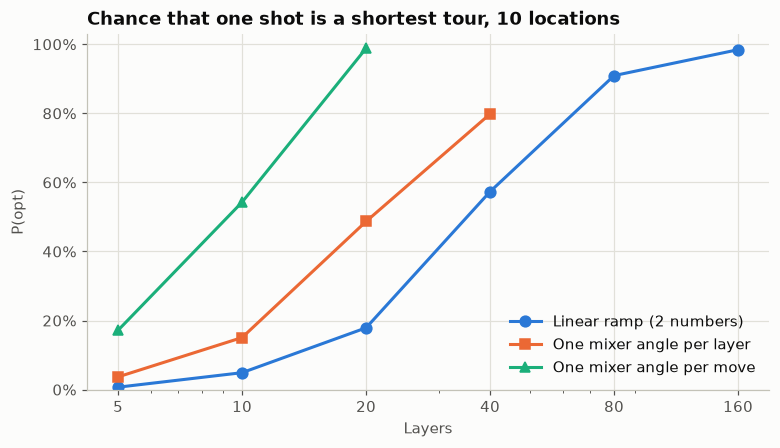

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for level, color, marker in (("ramp", BLUE, "o"), ("per layer", ORANGE, "s"), ("per move", AQUA, "^")):
    depths = [layers for (lv, layers) in results if lv == level]
    values = [results[level, layers]["p_opt"] for layers in depths]
    ax.plot(depths, values, color=color, marker=marker, label={"ramp": "Linear ramp (2 numbers)", "per layer": "One mixer angle per layer",
                                                              "per move": "One mixer angle per move"}[level])
ax.set_xscale("log"); ax.set_xticks(DEPTHS_RAMP); ax.set_xticklabels(DEPTHS_RAMP)
ax.set_ylim(0, 1.03); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("Layers"); ax.set_ylabel("P(opt)")
ax.set_title(f"Chance that one shot is a shortest tour, {N_LOCATIONS} locations")
ax.legend(loc="lower right")
plt.show()

## Sampling the circuit

We now measure one circuit, as a real run would. Each shot is a tour.

In [17]:
showcase_betas, showcase_gammas = angles[SHOWCASE][:2]
showcase_probs = qaoa.probabilities(showcase_betas, showcase_gammas)
rng = np.random.default_rng(SEED)
shots = rng.choice(len(showcase_probs), size=SHOTS, p=showcase_probs / showcase_probs.sum())
counts = Counter(tuple(int(v) for v in inst.tours[i]) for i in shots)

print(f"{SHOTS} shots of the '{SHOWCASE[0]}' circuit with {SHOWCASE[1]} layers: {len(counts)} different tours, all valid")
show_table(["Tour", "Length (km)", "Shots"],
           [["0 → " + " → ".join(map(str, tour)) + " → 0", f"{tour_lengths(np.array([tour]), inst.d)[0]:.3f}", count]
            for tour, count in counts.most_common(5)])

1000 shots of the 'per move' circuit with 20 layers: 11 different tours, all valid


| Tour | Length (km) | Shots |
|---|---|---|
| 0 → 2 → 9 → 6 → 8 → 7 → 5 → 4 → 3 → 1 → 0 | 40.205 | 498 |
| 0 → 1 → 3 → 4 → 5 → 7 → 8 → 6 → 9 → 2 → 0 | 40.205 | 493 |
| 0 → 3 → 4 → 5 → 7 → 6 → 1 → 8 → 2 → 9 → 0 | 60.320 | 1 |
| 0 → 5 → 4 → 3 → 2 → 8 → 1 → 9 → 7 → 6 → 0 | 70.662 | 1 |
| 0 → 3 → 1 → 7 → 8 → 4 → 6 → 9 → 5 → 2 → 0 | 71.567 | 1 |

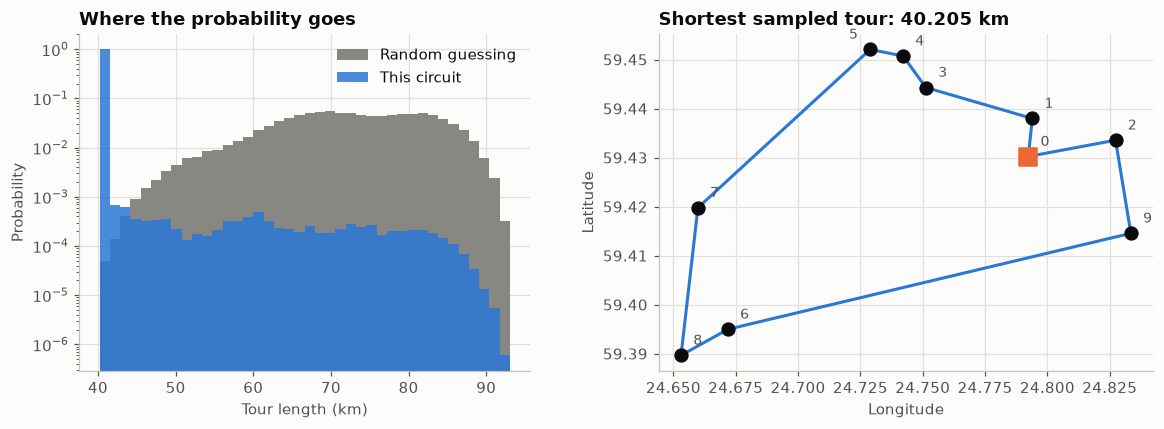

In [18]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1.25]})
bins = np.linspace(inst.km.min(), inst.km.max(), 41)
left.hist(inst.km, bins=bins, weights=np.full(len(inst.km), 1 / len(inst.km)), color=MUTED, label="Random guessing")
left.hist(inst.km, bins=bins, weights=showcase_probs, color=BLUE, alpha=0.85, label="This circuit")
left.set_yscale("log"); left.set_xlabel("Tour length (km)"); left.set_ylabel("Probability")
left.set_title("Where the probability goes"); left.legend()
sampled_best = min(counts, key=lambda tour: tour_lengths(np.array([tour]), inst.d)[0])
draw_map(right, N_LOCATIONS, sampled_best)
right.set_title(f"Shortest sampled tour: {tour_lengths(np.array([sampled_best]), inst.d)[0]:.3f} km")
plt.tight_layout(); plt.show()

## Check on real roads

The circuit minimised the symmetric distances. A loop can be driven in two directions, and on real one-way roads the two differ. We drive the shortest sampled loop both ways and compare with the true shortest route.

In [19]:
road_inst = make_instance(N_LOCATIONS, directed=True)
road_best = tuple(int(v) for v in road_inst.tours[road_inst.best][0])
forward = tour_lengths(np.array([sampled_best]), road_inst.d)[0]
backward = tour_lengths(np.array([sampled_best[::-1]]), road_inst.d)[0]
print(f"Sampled loop on real roads: {forward:.2f} km one way, {backward:.2f} km the other way")
print(f"True shortest route on real roads: {road_inst.km.min():.2f} km   0 → " + " → ".join(map(str, road_best)) + " → 0")
print(f"Loss from using symmetric distances: {min(forward, backward) / road_inst.km.min() - 1:.2%}")

Sampled loop on real roads: 41.67 km one way, 40.30 km the other way
True shortest route on real roads: 40.30 km   0 → 1 → 3 → 4 → 5 → 7 → 8 → 6 → 9 → 2 → 0
Loss from using symmetric distances: 0.00%


# 9. Benchmarks

## Does the 2-opt mixer matter?

We swap the mixer and keep everything else: same start state, same cost phase, linear ramp with the best slopes from a grid.

- **Adjacent swaps:** exchange the stops at two neighbouring steps. This is the standard mixer for orderings in reference 1.
- **All swaps:** exchange the stops at any two steps.
- **2-opt reversals:** this notebook.
- **Grover search:** the best any algorithm can do when it ignores the structure of the problem and only asks "is this tour a shortest one?" (reference 8). A Grover mixer on the same start state (reference 2) cannot beat it.

| Mixer | 10 layers | 20 layers | 40 layers | 80 layers |
|---|---|---|---|---|
| 2-opt reversals | 4.9 % | 17.9 % | 57.3 % | 90.9 % |
| All swaps | 0.6 % | 3.5 % | 11.9 % | 41.5 % |
| Adjacent swaps | 0.1 % | 0.5 % | 1.8 % | 3.6 % |
| Grover search | 0.2 % | 0.9 % | 3.6 % | 13.6 % |

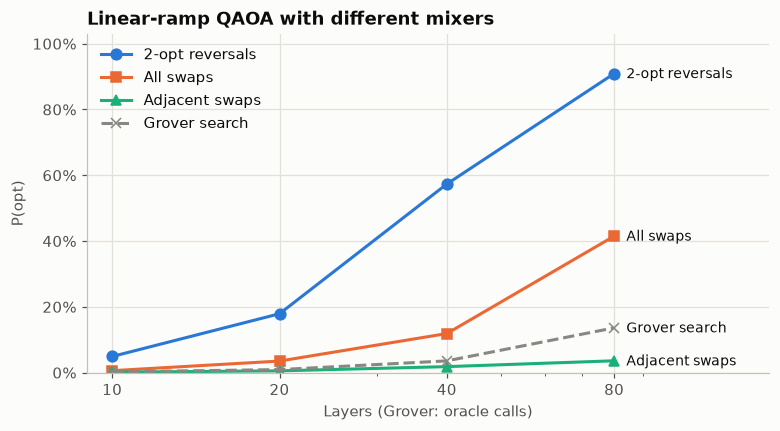

In [20]:
SLOPES_BETA_WIDE = (0.05, 0.1, 0.2, 0.3, 0.45, 0.7, 1.0)
DEPTHS_MIXERS = (10, 20, 40, 80)


def grover_p_opt(iterations, share):
    """Success probability of Grover search after `iterations` oracle calls, when `share` of the items are marked."""
    return math.sin(min((2 * iterations + 1) * math.asin(math.sqrt(share)), math.pi / 2)) ** 2


mixer_p_opt = {"2-opt reversals": [results["ramp", layers]["p_opt"] for layers in DEPTHS_MIXERS]}
for name, moves in (("All swaps", swap_moves(M, adjacent_only=False)), ("Adjacent swaps", swap_moves(M, adjacent_only=True))):
    other = TourQAOA(inst, moves)
    mixer_p_opt[name] = []
    for layers in DEPTHS_MIXERS:
        betas, gammas, _, _ = cached_angles(f"n{N_LOCATIONS}_{name.lower().replace(' ', '_')}_ramp_p{layers}",
                                            lambda: best_ramp(other, layers, slopes_beta=SLOPES_BETA_WIDE))
        mixer_p_opt[name].append(measures(inst, other.probabilities(betas, gammas), layers)["p_opt"])
    del other
mixer_p_opt["Grover search"] = [grover_p_opt(layers, P_RANDOM) for layers in DEPTHS_MIXERS]

show_table(["Mixer"] + [f"{layers} layers" for layers in DEPTHS_MIXERS],
           [[name] + [pct(v) for v in values] for name, values in mixer_p_opt.items()])

fig, ax = plt.subplots(figsize=(8, 4))
for (name, values), color, marker, style in zip(mixer_p_opt.items(), (BLUE, ORANGE, AQUA, MUTED), ("o", "s", "^", "x"), ("-", "-", "-", "--")):
    ax.plot(DEPTHS_MIXERS, values, color=color, marker=marker, linestyle=style, label=name)
    ax.annotate(name, (DEPTHS_MIXERS[-1], values[-1]), xytext=(8, -3), textcoords="offset points", fontsize=9)
ax.set_xscale("log"); ax.set_xticks(DEPTHS_MIXERS); ax.set_xticklabels(DEPTHS_MIXERS); ax.set_xlim(right=DEPTHS_MIXERS[-1] * 1.9)
ax.set_ylim(0, 1.03); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("Layers (Grover: oracle calls)"); ax.set_ylabel("P(opt)")
ax.set_title("Linear-ramp QAOA with different mixers"); ax.legend(loc="upper left")
plt.show()

## Cost to find the answer

How many cost evaluations does each method need for a 99 % chance of having seen a shortest tour?

- **Random sampling:** draw valid tours at random.
- **Grover adaptive search** (reference 7): the textbook quantum method with a proven square-root speed-up. It repeats Grover search for "a tour shorter than the best so far". It is simulated here from the exact Grover success probabilities.
- **QAOA:** shots × (layers + 1), for the best depth at each level of tuning. Training cost is extra and is listed in the next table.

In [21]:
def grover_adaptive_search(km, rng, growth=1.2):
    """Cost evaluations until Dürr-Høyer minimum finding first measures a shortest tour."""
    ordered = np.sort(km)
    current, evaluations, limit = ordered[rng.integers(len(km))], 1, 1.0
    while current > ordered[0] + 1e-9:
        shorter = int(np.searchsorted(ordered, current - 1e-9))   # tours the oracle marks
        iterations = int(rng.integers(0, math.ceil(limit)))
        evaluations += iterations + 1
        if rng.random() < math.sin((2 * iterations + 1) * math.asin(math.sqrt(shorter / len(km)))) ** 2:
            current, limit = ordered[rng.integers(shorter)], 1.0
        else:
            limit = min(limit * growth, math.sqrt(len(km)))
    return evaluations


rng = np.random.default_rng(SEED)
gas_runs = np.array([grover_adaptive_search(inst.km, rng) for _ in range(2000)])
cost_rows = [["Random sampling", f"{shots_for_99(P_RANDOM):,}"],
             ["Grover adaptive search", f"{int(np.percentile(gas_runs, 99)):,}"]]
for level in ("ramp", "per layer", "per move"):
    layers, r = min(((layers, r) for (lv, layers), r in results.items() if lv == level), key=lambda item: item[1]["evaluations"])
    cost_rows.append([f"QAOA, {level}, {layers} layers", f"{r['evaluations']:,} ({r['shots']} shot{'s' if r['shots'] != 1 else ''})"])
show_table(["Method", "Cost evaluations for 99 %"], cost_rows)
print(f"For scale: there are {len(inst.km) // inst.best.sum():,} different loops. Classical dynamic programming needs about "
      f"{N_LOCATIONS ** 2 * 2 ** N_LOCATIONS:,} steps.")

| Method | Cost evaluations for 99 % |
|---|---|
| Random sampling | 835,560 |
| Grover adaptive search | 2,947 |
| QAOA, ramp, 80 layers | 162 (2 shots) |
| QAOA, per layer, 40 layers | 123 (3 shots) |
| QAOA, per move, 20 layers | 42 (2 shots) |

For scale: there are 181,440 different loops. Classical dynamic programming needs about 102,400 steps.


## What training costs

The simulator gets all slopes from one forward and one backward pass. Hardware cannot: every tuned number needs at least two extra circuits per gradient, and every circuit needs many shots. The last column is that hardware estimate. For 10 locations there are only 362,880 tours, so the heavily trained circuits cost far more to train than listing every tour. They show what the circuit can express, not a practical way to find the answer.

In [22]:
training_rows = []
for (level, layers), (betas, gammas, evaluations, seconds) in angles.items():
    numbers = {"ramp": 2, "per layer": 2 * layers, "per move": (qaoa.num_moves + 1) * layers}[level]
    hardware = evaluations if level == "ramp" else evaluations * (1 + 2 * numbers)
    training_rows.append([level, layers, numbers, f"{evaluations:,}", f"{seconds:,.0f}", f"{hardware:,}"])
show_table(["Angles", "Layers", "Tuned numbers", "Simulator evaluations", "Seconds on this laptop", "Circuits on hardware"], training_rows)

| Angles | Layers | Tuned numbers | Simulator evaluations | Seconds on this laptop | Circuits on hardware |
|---|---|---|---|---|---|
| ramp | 5 | 2 | 24 | 3 | 24 |
| ramp | 10 | 2 | 24 | 4 | 24 |
| ramp | 20 | 2 | 24 | 6 | 24 |
| ramp | 40 | 2 | 24 | 10 | 24 |
| ramp | 80 | 2 | 24 | 18 | 24 |
| ramp | 160 | 2 | 24 | 34 | 24 |
| per layer | 5 | 10 | 105 | 27 | 2,205 |
| per layer | 10 | 20 | 290 | 124 | 11,890 |
| per layer | 20 | 40 | 277 | 219 | 22,437 |
| per layer | 40 | 80 | 636 | 839 | 102,396 |
| per move | 5 | 180 | 74 | 21 | 26,714 |
| per move | 10 | 360 | 142 | 59 | 102,382 |
| per move | 20 | 720 | 2,613 | 1,972 | 3,765,333 |

# 10. Scaling from 5 to 10 locations

Here nothing is tuned per instance. We take the ramp found for the largest instance and reuse it unchanged on the smaller ones. The z-score in the cost phase is what makes the same angles fit every size.

The number of tours grows from 24 to 362,880 between 5 and 10 locations. Watch how little P(opt) falls.

| Locations | Qubits | Valid tours | P(opt), QAOA ramp | P(opt), Grover | P(opt), random | Mean gap |
|---|---|---|---|---|---|---|
| 5 | 17 | 24 | 87.6 % | 100.0 % | 16.7 % | 3.3 % |
| 6 | 26 | 120 | 87.5 % | 100.0 % | 6.7 % | 1.6 % |
| 7 | 37 | 720 | 61.8 % | 100.0 % | 0.3 % | 1.9 % |
| 8 | 50 | 5,040 | 35.3 % | 53.1 % | 0.04 % | 3.0 % |
| 9 | 65 | 40,320 | 19.1 % | 8.1 % | 0.005 % | 3.1 % |
| 10 | 82 | 362,880 | 17.9 % | 0.9 % | 0.00055 % | 5.8 % |

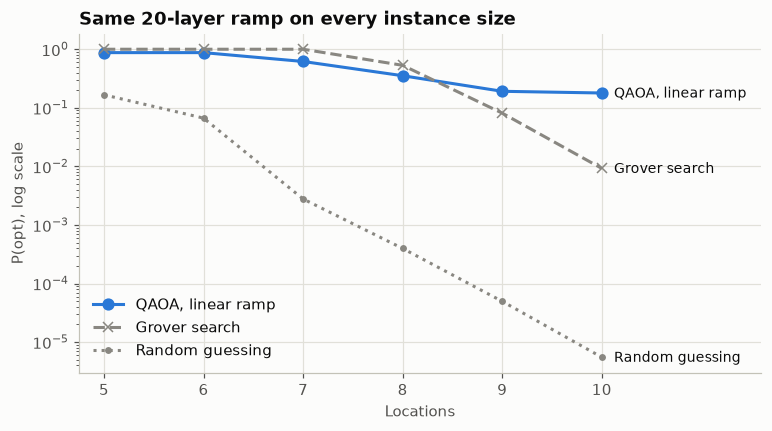

In [23]:
SCALING_LAYERS = 20
ramp_betas, ramp_gammas = angles["ramp", SCALING_LAYERS][:2]
scaling = []
for n in range(5, N_LOCATIONS + 1):
    smaller = make_instance(n)
    probs = TourQAOA(smaller, reversal_moves(n - 1)).probabilities(ramp_betas, ramp_gammas)
    scaling.append((n, len(smaller.km), measures(smaller, probs, SCALING_LAYERS), smaller.best.mean()))

show_table(["Locations", "Qubits", "Valid tours", "P(opt), QAOA ramp", "P(opt), Grover", "P(opt), random", "Mean gap"],
           [[n, (n - 1) ** 2 + 1, f"{tours:,}", pct(r["p_opt"]), pct(grover_p_opt(SCALING_LAYERS, share)), pct(share), pct(r["gap"])]
            for n, tours, r, share in scaling])

fig, ax = plt.subplots(figsize=(8, 4))
sizes = [row[0] for row in scaling]
for label, values, color, marker, style in (
        ("QAOA, linear ramp", [row[2]["p_opt"] for row in scaling], BLUE, "o", "-"),
        ("Grover search", [grover_p_opt(SCALING_LAYERS, row[3]) for row in scaling], MUTED, "x", "--"),
        ("Random guessing", [row[3] for row in scaling], MUTED, ".", ":")):
    ax.plot(sizes, values, color=color, marker=marker, linestyle=style, label=label)
    ax.annotate(label, (sizes[-1], values[-1]), xytext=(8, -3), textcoords="offset points", fontsize=9)
ax.set_yscale("log"); ax.set_xlim(right=sizes[-1] + 1.6); ax.set_xticks(sizes)
ax.set_xlabel("Locations"); ax.set_ylabel("P(opt), log scale")
ax.set_title(f"Same {SCALING_LAYERS}-layer ramp on every instance size"); ax.legend(loc="lower left")
plt.show()

# 11. Bonus: real one-way roads

The README uses symmetric distances because the edge encoding would need twice the qubits for directions. The position encoding does not: step order already says which way each road is driven. The same 82 qubits solve the real problem.

Two things change. The cost phase uses the directed distances, and the mixer also gets the move that reverses the whole route. There is now a single shortest tour instead of two, so the task is harder.

In [24]:
road_qaoa = TourQAOA(road_inst, reversal_moves(M, include_full=True))
road_angles = {("ramp", layers): cached_angles(f"n{N_LOCATIONS}_oneway_ramp_p{layers}", lambda: best_ramp(road_qaoa, layers))
               for layers in (20, 40, 80)}
road_angles["per move", 20] = cached_angles(
    f"n{N_LOCATIONS}_oneway_per_move_p20", lambda: train(road_qaoa, *road_angles["ramp", 20][:2], per_move=True, maxiter=2500))

road_results = {key: measures(road_inst, road_qaoa.probabilities(betas, gammas), key[1])
                for key, (betas, gammas, _, _) in road_angles.items()}
show_table(["Angles", "Layers", "P(opt)", "Mean gap", "Shots to 99 %"],
           [[level, layers, pct(r["p_opt"]), pct(r["gap"]), f"{r['shots']:,}"] for (level, layers), r in road_results.items()])
print(f"Shortest route on real roads: {road_inst.km.min():.2f} km. Random guessing: P(opt) = {pct(road_inst.best.mean())}")

| Angles | Layers | P(opt) | Mean gap | Shots to 99 % |
|---|---|---|---|---|
| ramp | 20 | 12.9 % | 10.7 % | 34 |
| ramp | 40 | 35.9 % | 3.6 % | 11 |
| ramp | 80 | 62.7 % | 4.1 % | 5 |
| per move | 20 | 99.5 % | 0.3 % | 1 |

Shortest route on real roads: 40.30 km. Random guessing: P(opt) = 0.00028 %


# 12. What the circuit would cost on hardware

We build the real 82-qubit circuit and translate it to the gates IBM devices use: CX plus one-qubit gates. No qubit layout is applied, so real devices would need more gates for routing.

In [25]:
def gate_cost(qc):
    native = transpile(qc, basis_gates=["cx", "rz", "sx", "x"], optimization_level=1, seed_transpiler=SEED)
    return native.count_ops().get("cx", 0), native.depth(lambda instruction: instruction.operation.num_qubits == 2)


start_circuit = QuantumCircuit(M * M + 1)
all_tours_state(start_circuit, M)
phase_circuit = QuantumCircuit(M * M + 1)
cost_phase(phase_circuit, 1.0, inst)
mixer_circuit = QuantumCircuit(M * M + 1)
for a, b in segments(M):
    reversal_mixer(mixer_circuit, 0.1, a, b, M)

parts = {"Start state (once)": gate_cost(start_circuit), "Cost phase (per layer)": gate_cost(phase_circuit),
         "2-opt mixer (per layer)": gate_cost(mixer_circuit)}
show_table(["Part", "CX gates", "Two-qubit depth"], [[name, f"{cx:,}", f"{depth:,}"] for name, (cx, depth) in parts.items()])

per_layer = parts["Cost phase (per layer)"][0] + parts["2-opt mixer (per layer)"][0]
show_table(["Layers", "Qubits", "CX gates in total", "CX error rate for a 50 % chance of a clean run"],
           [[layers, M * M + 1, f"{parts['Start state (once)'][0] + layers * per_layer:,}",
             f"{math.log(2) / (parts['Start state (once)'][0] + layers * per_layer):.1e}"] for layers in (5, 10, 20, 40)])

| Part | CX gates | Two-qubit depth |
|---|---|---|
| Start state (once) | 1,740 | 156 |
| Cost phase (per layer) | 1,152 | 156 |
| 2-opt mixer (per layer) | 8,316 | 5,943 |

| Layers | Qubits | CX gates in total | CX error rate for a 50 % chance of a clean run |
|---|---|---|---|
| 5 | 82 | 49,080 | 1.4e-05 |
| 10 | 82 | 96,420 | 7.2e-06 |
| 20 | 82 | 191,100 | 3.6e-06 |
| 40 | 82 | 380,460 | 1.8e-06 |

Today's best devices have a CX error rate near 10⁻³. Our notes measured 0.19 % on `ibm_kingston`. This circuit needs an error rate a few hundred times lower, which means error-corrected hardware.

For comparison, the encodings that fit today's devices pay in other ways:

| Encoding for 10 locations | Qubits | Valid share of bitstrings | Handles one-way roads |
|---|---|---|---|
| Edge, with penalties | 45 | about 10⁻⁸ | No |
| Position, with penalties | 81 | about 10⁻¹⁹ | Yes |
| Position, constraint-preserving (this notebook) | 82 | 100 % | Yes |

# 13. Score your own solution

`score_tours` computes the measures from section 8 for any sampler. Decode each shot to a tour first: the order in which locations 1 to n − 1 are visited. Count shots that are not valid tours under the key `None`.

In [26]:
def score_tours(counts, n=N_LOCATIONS, directed=False):
    """Measures for a dictionary {tour: shots}. Invalid shots go under the key None."""
    d = distances(n, directed)
    shortest = tour_lengths(all_tours(n), d).min()
    shots = sum(counts.values())
    valid = {tour: count for tour, count in counts.items() if tour is not None and sorted(tour) == list(range(1, n))}
    km = {tour: float(tour_lengths(np.array([tour]), d)[0]) for tour in valid}
    valid_shots = sum(valid.values())
    p_opt = sum(count for tour, count in valid.items() if km[tour] <= shortest + 1e-9) / shots
    return {"P(valid)": valid_shots / shots, "P(opt)": p_opt,
            "mean gap": sum(km[tour] * count for tour, count in valid.items()) / valid_shots / shortest - 1,
            "shots to 99 %": shots_for_99(p_opt), "best km": min(km.values()), "shortest km": float(shortest)}


print("This notebook's shots from section 8:")
for name, value in score_tours(counts).items():
    print(f"  {name}: {value:.4g}")

This notebook's shots from section 8:
  P(valid): 1
  P(opt): 0.991
  mean gap: 0.004181
  shots to 99 %: 1
  best km: 40.2
  shortest km: 40.2


# 14. References

1. S. Hadfield and others, "From the Quantum Approximate Optimization Algorithm to a Quantum Alternating Operator Ansatz", Algorithms 12, 34 (2019). Constraint-preserving mixers, including the swap mixers for orderings.
2. A. Bärtschi and S. Eidenbenz, "Grover Mixers for QAOA: Shifting Complexity from Mixer Design to State Preparation", IEEE QCE (2020). Starting from a superposition of all valid answers.
3. R. Herrman and others, "Multi-angle quantum approximate optimization algorithm", Scientific Reports 12, 6781 (2022). One angle per gate.
4. L. Li and others, "Quantum optimization with a novel Gibbs objective function and ansatz architecture search", Physical Review Research 2, 023074 (2020). The training objective.
5. J. A. Montañez-Barrera and K. Michielsen, "Towards a universal QAOA protocol: Evidence of a scaling advantage in solving some combinatorial optimization problems", arXiv:2405.09169 (2024). Linear-ramp angles.
6. T. Jones and J. Gacon, "Efficient calculation of gradients in classical simulations of variational quantum algorithms", arXiv:2009.02823 (2020). Adjoint differentiation.
7. C. Dürr and P. Høyer, "A quantum algorithm for finding the minimum", arXiv:quant-ph/9607014 (1996). Grover adaptive search.
8. C. Zalka, "Grover's quantum searching algorithm is optimal", Physical Review A 60, 2746 (1999).
9. G. A. Croes, "A method for solving traveling-salesman problems", Operations Research 6, 791 (1958). The 2-opt move.